In [1]:
import numpy as np
import netCDF4 as nc
import xarray as xr
import os
import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.lines as mlines
from matplotlib.colors import TwoSlopeNorm
import pandas as pd
import cartopy.crs as ccrs
# from ladcp_tools import *                  # load_all_stations, ...
# from tools import *                        # setup_map, load_satellite, load_eddies, plot_eddies
from tools_eg import *

In [2]:
EXTENT = None  # e.g. [10, 20, -42, -34]
lon_min, lon_max, lat_min, lat_max = 8, 25, -41, -34
extent = [lon_min, lon_max, lat_min, lat_max]

CRUISE_START = "2026-05-14"
CRUISE_END   = "2026-07-27"

ft = 10
# ADT colours: white exactly at 0, but each side stretched separately
# (ADT here is ~ -0.3 .. +1.5 m). Lower ADT_MIN -> darker cyclone blues,
# raise ADT_MAX -> fewer saturated anticyclone reds.
ADT_MIN, ADT_MAX = -0.3, 1.5
adt_norm = TwoSlopeNorm(vmin=ADT_MIN, vcenter=0, vmax=ADT_MAX)
levels = np.arange(ADT_MIN, ADT_MAX + 0.001, 0.02)
adt_ticks = [-0.3, 0, 0.3, 0.6, 0.9, 1.2, 1.5]

crs = ccrs.PlateCarree()
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max) / 2)


BASE = Path("/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS")
DIR_SADCP = BASE / "data/SADCP"
SADCP_FILES = {"OS150": DIR_SADCP / "WHIRLS_NB150_TOT_osite.nc",   # full cruise (README)
               "OS38": DIR_SADCP / "WHIRLS_BB38_TOT_osite.nc"}
DIR_LADCP = BASE / "data/LADCP/traitement_avec_SADCP"
DIR_SSH = BASE / "data/SSH"
DIR_EDDIES = {"TOEDDIES_better_ADT": BASE / "data/TOEDDIES/TOEDDIES_better_ADT",
              "TOEDDIES": BASE / "data/TOEDDIES/TOEDDIES"}
FNAME_BATHY = BASE / "data/bathymetry/etopo2.nc"
DIR_TRACKS = BASE / "figures/eddy_tracks"
DIR_CODE = BASE / "analysis"          # where ladcp_tools.py lives

DIR_DRIFTERS =  BASE / "data/DRIFTERS/drifters"
DIR_GEOJSON = BASE / "data/DRIFTERS/drifters_tracks.geojson"

DIR_MVP = BASE / "data/MVP_Data_processed"


# Animation
ANIM_START = "2026-07-01"                 # first drifter deployment
ANIM_END   = CRUISE_END                   # days without an ADT file are skipped
TAIL_DAYS  = 5                            # length of the track drawn behind each drifter (None = whole track)

# Drifter data: "csv" (folder of CSV snapshots, DIR_DRIFTERS) or "geojson" (DIR_GEOJSON)
DRIFTER_SOURCE = "csv"
FIRST_LAUNCH = "2026-07-01 05:00"         # fixes before this are bench tests (as in Solange's script)
FRAME_DIR = "whirls_drifters_animation"
OUT_MP4   = "whirls_drifters_animation.mp4"
FPS = 2                                   # frames (days) per second

os.makedirs(FRAME_DIR, exist_ok=True)

In [3]:
# ----------------------------------------------------------------------------
# Things loaded ONCE (they don't change from day to day)
# ----------------------------------------------------------------------------
# Bathymetry
bathymetry_data = xr.open_dataset(FNAME_BATHY)
lon_subset = bathymetry_data["lon"].sel(lon=slice(lon_min, lon_max))
lat_subset = bathymetry_data["lat"].sel(lat=slice(lat_min, lat_max))
depth_subset = bathymetry_data["topo"].sel(lon=slice(lon_min, lon_max),
                                           lat=slice(lat_min, lat_max))

# File lists
daily_ssh_files = sorted(os.listdir(DIR_SSH))
eddy_files_better = sorted(os.listdir(DIR_EDDIES['TOEDDIES_better_ADT']))
eddy_files_std = sorted(os.listdir(DIR_EDDIES['TOEDDIES']))

type_SADCP = "OS38"
sadcp = nc.Dataset(SADCP_FILES[type_SADCP])


In [4]:
transect = "Transect 12"
transect_path = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/data/MVP_Data_processed/{transect}/'
out_dir = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/figures/mvp/{transect}/'
if not os.path.isdir(out_dir):
    os.mkdir(out_dir)

In [5]:
files = sorted(Path(transect_path).glob("*.csv"))
dfs = []
for k, f in enumerate(files):
    df = pd.read_csv(f)
    df["CAST"] = k          # one processed CSV file = one MVP cast
    dfs.append(df)
mvp_trans = pd.concat(dfs, ignore_index=True)
print(len(files), "files")

118 files


In [6]:
sadcp_all = {}
for inst in ["OS150", "OS38"]:
    s = cascade_add_time(xr.open_dataset(SADCP_FILES[inst]))
    s = s.sortby("time")
    s = s.isel(time=~s.indexes["time"].duplicated())
    sadcp_all[inst] = sadcp_for_transect(mvp_trans, s)

sadcp_tr  = sadcp_all["OS150"]          # used for positions (and in the cell below)
sadcp_mvp = sadcp_on_mvp_times(mvp_trans, sadcp_tr, max_gap="30min")

mvp_trans["LON (°E)"] = mvp_trans["LON (°E)"].fillna(pd.Series(sadcp_mvp["LONGITUDE"].values, index=mvp_trans.index))
mvp_trans["LAT (°N)"] = mvp_trans["LAT (°N)"].fillna(pd.Series(sadcp_mvp["LATITUDE"].values, index=mvp_trans.index))

print("MVP samples without position:", mvp_trans["LAT (°N)"].isna().sum(), "of", len(mvp_trans))

MVP samples without position: 0 of 494501


In [7]:
# OS150 above Z_SPLIT (150 m), OS38 below: sadcp_window keeps the right depths for each
a = sadcp_window("OS150", sadcp=cascade_to_window_format(sadcp_all["OS150"], pgood_min=50))
b = sadcp_window("OS38",  sadcp=cascade_to_window_format(sadcp_all["OS38"],  pgood_min=50))
print("OS150:", len(a["time"]), "profiles,", a["z"].min(), "-", a["z"].max(), "m")
print("OS38: ", len(b["time"]), "profiles,", b["z"].min(), "-", b["z"].max(), "m")

# put both on the same time axis (both are 10-min means), then stack in depth
t = np.union1d(a["time"], b["time"])
def on_t(d, key):
    out = np.full((len(t),) + d[key].shape[1:], np.nan)
    out[np.searchsorted(t, d["time"])] = d[key]
    return out

lon_a, lat_a = on_t(a, "lon"), on_t(a, "lat")
sadcp_mvp_processed = dict(
    time=t,
    lon=np.where(np.isnan(lon_a), on_t(b, "lon"), lon_a),
    lat=np.where(np.isnan(lat_a), on_t(b, "lat"), lat_a),
    z=np.concatenate([a["z"], b["z"]]),
    u=np.concatenate([on_t(a, "u"), on_t(b, "u")], axis=1),
    v=np.concatenate([on_t(a, "v"), on_t(b, "v")], axis=1))
print(len(sadcp_mvp_processed["time"]), "SADCP profiles,",
      sadcp_mvp_processed["z"].min(), "-", sadcp_mvp_processed["z"].max(), "m")

Calculating Mean
  ! PGOOD_ADCP is all 0 in this file -> PGOOD mask skipped
Calculating Mean
OS150: 146 profiles, 24.260000228881836 - 144.25999450683594 m
OS38:  146 profiles, 167.4600067138672 - 983.4600219726562 m
146 SADCP profiles, 24.260000228881836 - 983.4600219726562 m


eddies crossed: ['C (15 km from track)', 'AC (58 km from track)']
118 casts used


/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/analysis/tools_eg.py:1160: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, p, data, cmap=cmap, shading="nearest",


  C: TOEddies center at -16 km, outside section (-2-272 km) -> not marked
  C: Nencioli minimum on the edge of the search box -> no centre


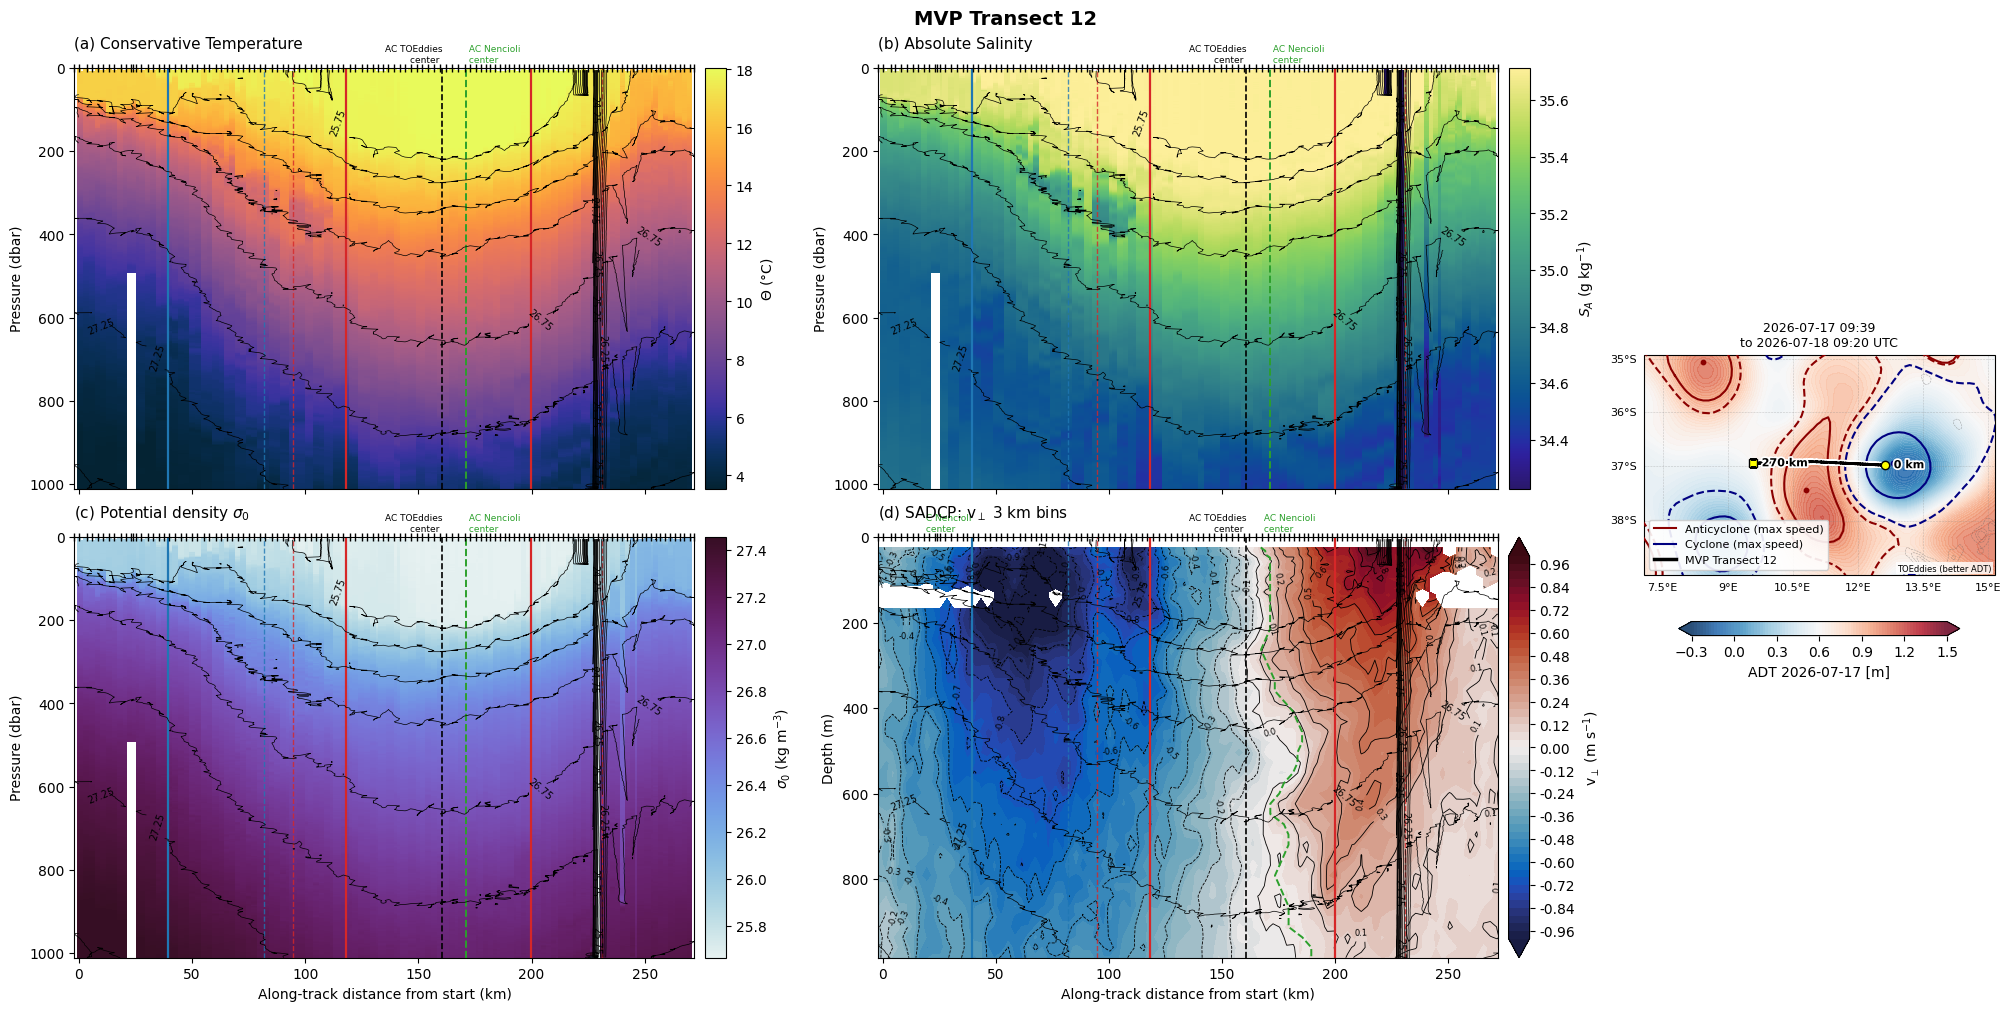

In [8]:
# ---------------- map background for the combined figure ----------------
out_dir = str(BASE / "figures/mvp") + f"/{transect}/"

date = pd.to_datetime(mvp_trans["TIME"]).median().strftime("%Y-%m-%d")
date_compact = date.replace("-", "")
ssh = load_satellite(DIR_SSH / [f for f in daily_ssh_files if date in f or date_compact in f][0])
eddy_files, eddy_source = get_eddy_files(date_compact, date)

edds = eddies_on_transect(eddy_files, mvp_trans["LON (°E)"].values, mvp_trans["LAT (°N)"].values)
print("eddies crossed:", [("C" if e["cyc"] else "AC") + f" ({e['dist_km']:.0f} km from track)" for e in edds])

# ---------------- SADCP for zeta (PV) ----------------
ds = sadcp_tr                      # ADCP subset for this transect (sadcp_mvp is ~1 GB, not needed)
zdim = ds["depth"].dims[0]
u = ds["UVEL_ADCP_CORTIDE"].transpose("time", zdim).values
v = ds["VVEL_ADCP_CORTIDE"].transpose("time", zdim).values
pg = ds["PGOOD_ADCP"].transpose("time", zdim).values

u[pg < 50] = np.nan
v[pg < 50] = np.nan

args = [ssh, eddy_files, transect, eddy_source, adt_ticks, date, levels]
# ---------------- map + Theta / S_A / sigma0 ----------------
sec, fig, axs = process_transect(
    mvp_trans, adcp=sadcp_mvp_processed, cast_col="CAST",
    map_draw=draw_background,      # map_extent=extent  -> whole region instead of zoom
    map_args = args,
    title=f"MVP {transect}",
    eddy=edds,
    savepath=out_dir + f"{transect}_sections_hydro_adcp.png",
    flip_x = False)
plt.show()

zeta/f, upper 300 m: min -0.42 (anticyclonic), max 0.91 (cyclonic)


/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_54700/174808902.py:63: UserWarning: The following kwargs were not used by contour: 'shading'
  pc = ax.contourf(xg, z_a, ro.T, cmap="RdBu_r", levels=levels, shading="nearest", extend='both')


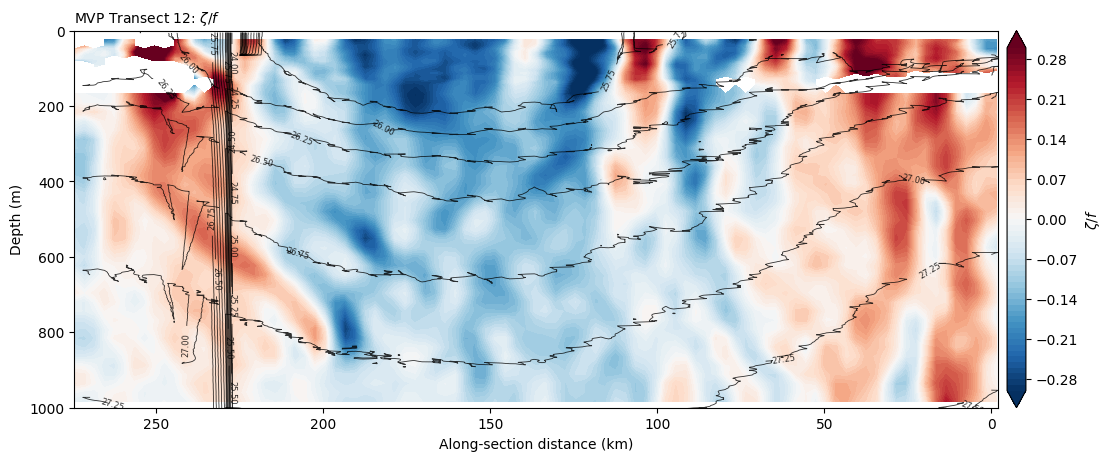

In [9]:
# ---------------- normalized relative vorticity zeta/f from SADCP ----------------
from scipy.ndimage import uniform_filter1d
import cmocean

DX_KM      = DS_KM   # along-track bin (km); same 3 km bins as panel (d)
SMOOTH_X   = 3       # running mean over this many bins along x before differentiating (1 = none)
SMOOTH_Z   = 3       # running mean over this many SADCP levels in depth (1 = none)
PMV_FACTOR = 1       # 1 = Rudnick (Barabinot 2025), 2 = poor man's vorticity
RO_LIM     = 0.3    # colour limit for zeta/f; None = 98th percentile of |zeta/f|
ZMAX       = 1000    # m, bottom of the plot
FLIP_X     = True    # same orientation as the section figure above


def nan_smooth(a, size, axis):
    """Running mean that ignores NaNs (NaNs stay NaN)."""
    if size <= 1:
        return a
    w = np.isfinite(a).astype(float)
    num = uniform_filter1d(np.where(w > 0, a, 0.0), size, axis=axis, mode="nearest")
    den = uniform_filter1d(w, size, axis=axis, mode="nearest")
    out = num / np.where(den > 0, den, np.nan)
    out[w == 0] = np.nan
    return out


ad = sadcp_mvp_processed                      # OS150 above 150 m + OS38 below, 10-min profiles
z_a = np.asarray(ad["z"], float)

# 1) cross-track velocity on the same x axis as the MVP section (origin = first cast,
#    +x = first -> last cast). v_perp > 0 to the LEFT of +x, so (x, v_perp) is right-handed
#    and zeta = d v_perp / dx has the usual sign (zeta > 0 counter-clockwise).
s_m, _ = along_track_x(np.asarray(ad["lon"], float), np.asarray(ad["lat"], float),
                       sec["lon"][0], sec["lat"][0], sec["xdir"])
s = s_m / 1e3
ex = sec["xdir"]
v_perp = -ad["u"] * ex[1] + ad["v"] * ex[0]

# 2) bin along x, fill small vertical gaps (OS150/OS38 seam), smooth
edges = np.arange(np.floor(np.nanmin(s)), np.ceil(np.nanmax(s)) + DX_KM, DX_KM)
xg, V, cnt = bin_columns(s, v_perp, edges)
_, LATb, _ = bin_columns(s, np.asarray(ad["lat"], float)[:, None], edges)
V = fill_z_gaps(V, z_a)
V = nan_smooth(nan_smooth(V, SMOOTH_X, axis=0), SMOOTH_Z, axis=1)

# 3) zeta = d v_perp / dx (centred differences), and f at each bin's latitude
zeta = PMV_FACTOR * np.gradient(V, xg * 1e3, axis=0)            # s^-1, shape (nx, nz)
lat_b = LATb[:, 0]
lat_b = np.where(np.isfinite(lat_b), lat_b, np.nanmean(lat_b))
f_b = 2 * OMEGA * np.sin(np.deg2rad(lat_b))                       # < 0 in the south
ro = zeta / f_b[:, None]                                          # zeta / f

# zeta/f < 0 = anticyclonic in both hemispheres (Agulhas rings: zeta > 0, f < 0)
vort = dict(x=xg, z=z_a, v_perp=V, zeta=zeta, f=f_b, ro=ro, n_fixes=cnt)

top = z_a <= 300
print(f"zeta/f, upper 300 m: min {np.nanmin(ro[:, top]):.2f} (anticyclonic), "
      f"max {np.nanmax(ro[:, top]):.2f} (cyclonic)")

# 4) figure: zeta/f, zeta = 0 contour (eddy boundary, Barabinot 2025), sigma0, v_perp
lim = RO_LIM or max(0.1, np.round(np.nanpercentile(np.abs(ro), 98), 1))
fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
levels = np.linspace(-lim, lim, int(RO_LIM * 200) + 1)
pc = ax.contourf(xg, z_a, ro.T, cmap="RdBu_r", levels=levels, shading="nearest", extend='both')
# ax.contour(xg, z_a, zeta.T, levels=[0], colors="k", linewidths=1.2)
# cs = ax.contour(xg, z_a, V.T, levels=np.arange(-1.5, 1.51, 0.2), colors="gray",
#                 linewidths=0.5, linestyles="solid")
# ax.clabel(cs, fmt="%.1f", fontsize=6)
sig_lev = np.arange(np.floor(np.nanmin(sec["sig0"]) * 4) / 4, np.nanmax(sec["sig0"]), 0.25)
cs2 = ax.contour(sec["x"] / 1e3, sec["p"], sec["sig0"], levels=sig_lev,      # p (dbar) ~ z (m)
                 colors="black", linewidths=0.6, alpha=0.8)
ax.clabel(cs2, fmt="%.2f", fontsize=6)
ax.set_ylim(ZMAX, 0)
FLIP_X = True
if FLIP_X:
    ax.invert_xaxis()
ax.set_xlabel("Along-section distance (km)")
ax.set_ylabel("Depth (m)")
cb = fig.colorbar(pc, ax=ax, pad=0.01, extend="both")
cb.set_label(r"$\zeta / f$")
ax.set_title(rf"MVP {transect}: $\zeta/f$", loc="left", fontsize=10)
fig.savefig(out_dir + f"{transect}_zeta_over_f.png", dpi=300)
plt.show()

In [10]:
# ---------------- Ertel PV on the section (Barabinot et al. 2025) ----------------
# 2-D section, x along the section, v_perp across it (+ to the LEFT of +x), z up:
#   EPV   = omega . grad(b) = (f + zeta) N^2  -  (dv_perp/dz)(db/dx)
#   EPV_z = (f + zeta) N^2              vertical part
#   EPV_x = -(dv_perp/dz)(db/dx)        horizontal (baroclinic) part
# zeta = dv_perp/dx (cell above), b = -g (rho_theta - rho0)/rho0 from sigma0 (MVP), N^2 = db/dz.
# Everything on one grid: the 3 km x bins of the zeta cell and DZ_EPV-m depth bins.
RHO0 = 1025.0          # kg m^-3
DZ_EPV = 8.0           # m, depth bins of the common grid
Z_TOP_EPV = None       # m, top of the grid; None = shallowest SADCP level
ZMAX_EPV = ZMAX        # m, bottom of the grid (also limited by SADCP and MVP depth)
SMOOTH_X_B = SMOOTH_X  # running mean on b along x (bins), as for v_perp
SMOOTH_Z_B = 3         # running mean on b in depth (DZ_EPV bins) before N^2 and db/dx
MAX_XGAP_KM = 10       # fill MVP gaps along x up to this size (km), linearly

xg_e = vort["x"]                                              # km, bin centres
edges_e = np.r_[xg_e - DX_KM / 2, xg_e[-1] + DX_KM / 2]
lat_sec = np.nanmean(sec["lat"])
depth_mvp = -gsw.z_from_p(sec["p"], lat_sec)                  # dbar -> m (positive down)

z_top = Z_TOP_EPV or np.nanmin(z_a[np.isfinite(vort["v_perp"]).any(axis=0)])
z_bot = min(ZMAX_EPV, np.nanmax(z_a[np.isfinite(vort["v_perp"]).any(axis=0)]),
            np.nanmax(depth_mvp[np.isfinite(sec["sig0"]).any(axis=1)]))
z_edges_e = np.arange(z_top - DZ_EPV / 2, z_bot + DZ_EPV / 2, DZ_EPV)
z_e = 0.5 * (z_edges_e[1:] + z_edges_e[:-1])                 # m, positive down


def interp_rows(A, z_in, z_out):
    """Interpolate each row of A (n, len(z_in)) onto z_out, NaN outside the data / in NaN gaps."""
    out = np.full((A.shape[0], len(z_out)), np.nan)
    for i, row in enumerate(A):
        ok = np.isfinite(row)
        if ok.sum() >= 2:
            out[i] = np.interp(z_out, z_in[ok], row[ok], left=np.nan, right=np.nan)
    return out


def fill_x_gaps(A, max_bins):
    """Linear fill of NaN gaps along x (axis 0) of up to max_bins bins, no extrapolation."""
    return pd.DataFrame(A).interpolate(axis=0, limit=max_bins, limit_area="inside").values


# 1) velocity: v_perp (already binned/smoothed in the zeta cell) on the depth grid
V_e = interp_rows(vort["v_perp"], z_a, z_e)                       # (nx, nz)
zeta_e = PMV_FACTOR * np.gradient(V_e, xg_e * 1e3, axis=0)        # s^-1
dvdz_e = -np.gradient(V_e, z_e, axis=1)                           # d/dz with z UP (s^-1)
f_e = vort["f"]                                                   # (nx,), < 0 here

# 2) buoyancy from the MVP: casts -> 3 km x bins -> DZ_EPV depth bins
b_sec = -G * (sec["sig0"] + 1000.0 - RHO0) / RHO0                 # (np, ncast), m s^-2
_, Bx, n_cast_bin = bin_columns(sec["x"] / 1e3, b_sec.T, edges_e)    # (nx, np)
_, Bxz, _ = bin_columns(depth_mvp, Bx.T, z_edges_e)                  # (nz, nx)
B_e = fill_x_gaps(Bxz.T, int(MAX_XGAP_KM // DX_KM))
B_e = nan_smooth(nan_smooth(B_e, SMOOTH_X_B, axis=0), SMOOTH_Z_B, axis=1)

N2_e = -np.gradient(B_e, z_e, axis=1)                             # s^-2 (z up)
dbdx_e = np.gradient(B_e, xg_e * 1e3, axis=0)                     # s^-2

# 3) Ertel PV and its two parts (s^-3)
EPV_z = (f_e[:, None] + zeta_e) * N2_e
EPV_x = -dvdz_e * dbdx_e
EPV = EPV_z + EPV_x

epv = dict(x=xg_e, z=z_e, f=f_e, v_perp=V_e, zeta=zeta_e, dvdz=dvdz_e, b=B_e, N2=N2_e,
           dbdx=dbdx_e, EPV=EPV, EPV_z=EPV_z, EPV_x=EPV_x,
           sig0=-(B_e * RHO0 / G) + RHO0 - 1000.0)                  # sigma0 on the grid

ok = np.isfinite(EPV_x) & np.isfinite(EPV_z)
print(f"grid: {len(xg_e)} x-bins ({DX_KM:.0f} km) x {len(z_e)} z-bins ({DZ_EPV:.0f} m), "
      f"{z_e[0]:.0f}-{z_e[-1]:.0f} m; EPV defined on {ok.mean() * 100:.0f}% of it")
print(f"x-bins with >= 1 MVP cast: {(n_cast_bin > 0).sum()} of {len(xg_e)}")
print(f"EPV_z: median {np.nanmedian(EPV_z):.2e} s^-3 (sign of f: stable water has EPV_z < 0 here)")
print(f"EPV_x > 0 (opposite sign to f, as thermal wind implies) on "
      f"{(EPV_x[ok] > 0).mean() * 100:.0f}% of the points; median |EPV_x/EPV_z| = "
      f"{np.nanmedian(np.abs(EPV_x[ok] / EPV_z[ok])):.2f}")

grid: 93 x-bins (3 km) x 120 z-bins (8 m), 24-976 m; EPV defined on 98% of it
x-bins with >= 1 MVP cast: 92 of 93
EPV_z: median -9.01e-10 s^-3 (sign of f: stable water has EPV_z < 0 here)
EPV_x > 0 (opposite sign to f, as thermal wind implies) on 71% of the points; median |EPV_x/EPV_z| = 0.01


In [ ]:
# ---------------- background (reference) profiles: CTD (precomputed) and WOA ----------------
# CTD: mean of all CTD casts, computed ONCE by make_ctd_reference_profile.py and saved in
#      data/CTD/ctd_reference_profile.nc (rerun the script if the CTD data change;
#      `python make_ctd_reference_profile.py --outside` -> casts outside every eddy only).
# WOA: July climatology around the eddy centre, so it depends on the transect -> computed here.
from make_ctd_reference_profile import load_ctd_reference

CTD_REF_NC = BASE / "data/CTD/ctd_reference_profile.nc"
ctd_ref, ref_used, CT_all, SA_all, p_ref = load_ctd_reference(CTD_REF_NC)
print(f"CTD reference: {len(ref_used)} casts, 0-{ctd_ref['p'].max():.0f} dbar, "
      f"sigma0 {ctd_ref['sig0'].min():.3f}..{ctd_ref['sig0'].max():.3f}")
print(f"lightest MVP sigma0 in this transect: {np.nanmin(sec['sig0']):.3f}")

# ---- WOA ----
DIR_WOA = BASE / "data/woa"
WOA_RADIUS_KM = 100                    # WOA grid points within this distance of the eddy centre
EDDY_IDX = 1 if len(edds) > 1 else 0   # anom_woa: second eddy crossed if there are two

eddy_lon, eddy_lat = edds[EDDY_IDX]["center"]
print(f"WOA reference around the {'cyclone' if edds[EDDY_IDX]['cyc'] else 'anticyclone'} "
      f"at {eddy_lon:.3f}°E, {eddy_lat:.3f}°N")

ds_woa_temp = nc.Dataset(DIR_WOA / "temp" / os.listdir(DIR_WOA / "temp")[0])
ds_woa_sal = nc.Dataset(DIR_WOA / "salt" / os.listdir(DIR_WOA / "salt")[0])
lon2d, lat2d = np.meshgrid(np.array(ds_woa_temp["lon"][:]), np.array(ds_woa_temp["lat"][:]))
distance = np.hypot((lat2d - eddy_lat) * 111.0,
                    (lon2d - eddy_lon) * 111.0 * np.cos(np.deg2rad(eddy_lat)))
temp = np.ma.filled(ds_woa_temp["t_an"][:], np.nan)
sal = np.ma.filled(ds_woa_sal["s_an"][:], np.nan)
mask = (distance <= WOA_RADIUS_KM) & np.isfinite(temp[0, 0]) & np.isfinite(sal[0, 0])
woa_lons_eddy, woa_lats_eddy = lon2d[mask], lat2d[mask]
temp_profile = np.squeeze(np.nanmean(temp[..., mask], axis=-1))
sal_profile = np.squeeze(np.nanmean(sal[..., mask], axis=-1))
depth_woa = np.array(ds_woa_temp["depth"][:])
woa_lon_ref, woa_lat_ref = np.mean(woa_lons_eddy), np.mean(woa_lats_eddy)


def woa_reference(tref, sref, depth_woa, lon_woa, lat_woa):
    """Averaged WOA profile -> dict(p, CT, SA, sig0) on the WOA levels that have data (anom_woa)."""
    depth_woa = np.asarray(depth_woa, float)
    tref, sref = np.squeeze(tref), np.squeeze(sref)
    woa_press = gsw.p_from_z(-depth_woa, lat_woa)
    SA = gsw.SA_from_SP(sref, woa_press, lon_woa, lat_woa)
    CT = gsw.CT_from_t(SA, tref, woa_press)
    ok = np.isfinite(SA) & np.isfinite(CT)
    return dict(p=woa_press[ok], CT=CT[ok], SA=SA[ok], sig0=gsw.sigma0(SA, CT)[ok])


woa_ref = woa_reference(temp_profile, sal_profile, depth_woa, woa_lon_ref, woa_lat_ref)
print(f"{mask.sum()} WOA profiles ({os.listdir(DIR_WOA / 'temp')[0]}), "
      f"0-{woa_ref['p'].max():.0f} dbar, sigma0 {woa_ref['sig0'].min():.3f}..{woa_ref['sig0'].max():.3f}")

In [13]:
# ---------------- EPV_z anomaly ON ISOPYCNALS relative to a background, and ratio to EPV_x ----------------
# Barabinot et al. eqs. 11, 14:  EPV_ref = f N^2_ref,   dEPV_z(sigma0) = EPV_z(sigma0) - f N^2_ref(sigma0)
# i.e. at each (x, z) of the section, N^2_ref is the background stratification ON THE SAME
# ISOPYCNAL (wherever that isopycnal sits in the background profile), not at the same depth.
#   R = dEPV_z / EPV_x        |R| >> 1: the anomaly is set by the vertical part
REF_MODE = "isopycnal"  # "isopycnal" (Barabinot) or "depth" (N^2_ref at the same depth, for comparison)
ISO_OUTCROP = "nan" # sigma0 lighter than the lightest background water (isopycnal outcrops in the
                        # background): "nan" = undefined (strict), "surface" = use the N^2 of the
                        # background's surface mixed layer (N2_ml below)
REF_ZMIN = 10.0         # m: background levels shallower than this are ignored (skin / diurnal layer;
                        # WOA has a 0-5 m density jump that otherwise dominates the surface N^2)
MLD_DSIG = 0.03         # kg m^-3: background mixed-layer depth, sigma0 = sigma0(REF_ZMIN) + MLD_DSIG
DZ_REF = DZ_EPV         # m, depth bins for the background profile (from the surface)
WOA_N2_SMOOTH_M = 150   # m, running mean on N^2_ref for coarse profiles (WOA)
EPV_X_MIN = 1e-13       # s^-3: R is masked where |EPV_x| is below this (division by ~0)


def reference_profile(ref, lat0, dz=DZ_REF):
    """Background b, sigma0 and N^2 on its OWN depth grid, from REF_ZMIN to its deepest level.
    Dense profiles (CTD, ~1 dbar): bin means of b in dz bins, smoothed, N^2 = -db/dz, smoothed.
    Coarse profiles (WOA): N^2 on the native layers (layer mid-depths), linearly interpolated
    onto the grid and smoothed over WOA_N2_SMOOTH_M; b linearly interpolated between levels."""
    d = -gsw.z_from_p(ref["p"], lat0)
    b = -G * (ref["sig0"] + 1000.0 - RHO0) / RHO0
    o = np.argsort(d)
    d, b = d[o], b[o]
    keep = d >= REF_ZMIN
    d, b = d[keep], b[keep]
    # mixed-layer N^2 of the background (unsmoothed): b from REF_ZMIN to the mixed-layer depth
    sig_raw = -(b * RHO0 / G) + RHO0 - 1000.0
    below = np.where(sig_raw >= sig_raw[0] + MLD_DSIG)[0]
    mld = d[below[0]] if below.size else d[-1]
    N2_ml = -(np.interp(mld, d, b) - b[0]) / (mld - d[0])
    edges = np.arange(REF_ZMIN, d.max() + dz, dz)
    zr = 0.5 * (edges[1:] + edges[:-1])
    if np.nanmedian(np.diff(d)) <= dz:                           # dense (CTD)
        _, bb, _ = bin_columns(d, b[:, None], edges)
        bb = nan_smooth(bb[:, 0][None, :], SMOOTH_Z_B, axis=1)[0]
        N2 = nan_smooth(-np.gradient(bb, zr)[None, :], SMOOTH_Z_B, axis=1)[0]
    else:                                                        # coarse (WOA)
        bb = np.interp(zr, d, b, left=np.nan, right=np.nan)
        N2 = np.interp(zr, 0.5 * (d[1:] + d[:-1]), -np.diff(b) / np.diff(d),
                       left=np.nan, right=np.nan)
        N2 = nan_smooth(N2[None, :], max(1, int(round(WOA_N2_SMOOTH_M / dz))), axis=1)[0]
    sig = -(bb * RHO0 / G) + RHO0 - 1000.0
    return dict(z=zr, b=bb, sig0=sig, N2=N2, mld=mld, N2_ml=N2_ml)


def N2_on_sigma(prof, sig_q, outcrop=ISO_OUTCROP):
    """Background N^2 on the isopycnals sig_q (any shape). Background sorted in sigma0
    (a small inversion would make it non-monotonic); NaN for sigma0 denser than the background."""
    ok = np.isfinite(prof["sig0"]) & np.isfinite(prof["N2"])
    s = np.maximum.accumulate(prof["sig0"][ok])                  # monotonic with depth
    s, i = np.unique(s, return_index=True)
    n2 = prof["N2"][ok][i]
    left = prof["N2_ml"] if outcrop == "surface" else np.nan
    return np.interp(sig_q, s, n2, left=left, right=np.nan), s[0]


def epv_anomaly(epv, ref, mode=REF_MODE, outcrop=ISO_OUTCROP):
    prof = reference_profile(ref, lat_sec)
    if mode == "isopycnal":
        N2r, sig_min = N2_on_sigma(prof, epv["sig0"], outcrop)
    elif mode == "depth":
        N2r = np.broadcast_to(np.interp(epv["z"], prof["z"], prof["N2"], left=np.nan, right=np.nan),
                              epv["N2"].shape)
        sig_min = np.nan
    else:
        raise ValueError(f"mode must be 'isopycnal' or 'depth', not {mode!r}")
    f2 = epv["f"][:, None]
    dEPV_z = epv["EPV_z"] - f2 * N2r
    with np.errstate(divide="ignore", invalid="ignore"):
        R = np.where(np.abs(epv["EPV_x"]) > EPV_X_MIN, dEPV_z / epv["EPV_x"], np.nan)
    return dict(prof=prof, N2r=N2r, EPV_ref=f2 * N2r, dEPV_z=dEPV_z, R=R, mode=mode,
                outcrop=outcrop, sig_ref_min=sig_min,
                outcropping=(epv["sig0"] < sig_min) if mode == "isopycnal" else None)


epv_anoms = {"WOA": epv_anomaly(epv, woa_ref), "CTD": epv_anomaly(epv, ctd_ref)}
for name, an in epv_anoms.items():
    ok = np.isfinite(epv["EPV_z"])
    msg = f"{name} ({an['mode']}"
    if an["mode"] == "isopycnal":
        msg += (f", outcrop={an['outcrop']}): lightest background sigma0 {an['sig_ref_min']:.3f}; "
                f"{an['outcropping'][ok].mean() * 100:.0f}% of the section is lighter; background "
                f"MLD {an['prof']['mld']:.0f} m, N2_ml {an['prof']['N2_ml']:.1e} s^-2")
    lr = np.abs(an["R"])
    print(msg + f"); dEPV_z defined on {np.isfinite(an['dEPV_z'][ok]).mean() * 100:.0f}% of the "
          f"section, median |R| = {np.nanmedian(lr):.1f}")

WOA (isopycnal, outcrop=nan): lightest background sigma0 26.138; 19% of the section is lighter; background MLD 100 m, N2_ml 4.2e-06 s^-2); dEPV_z defined on 81% of the section, median |R| = 22.2
CTD (isopycnal, outcrop=nan): lightest background sigma0 25.864; 10% of the section is lighter; background MLD 43 m, N2_ml 8.8e-06 s^-2); dEPV_z defined on 89% of the section, median |R| = 17.6


/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_54700/2319822925.py:38: UserWarning: The following kwargs were not used by contour: 'path_effects'
  ax.contour(x, z, core.T.astype(float), levels=[0.5], colors="red", linewidths=1.8,


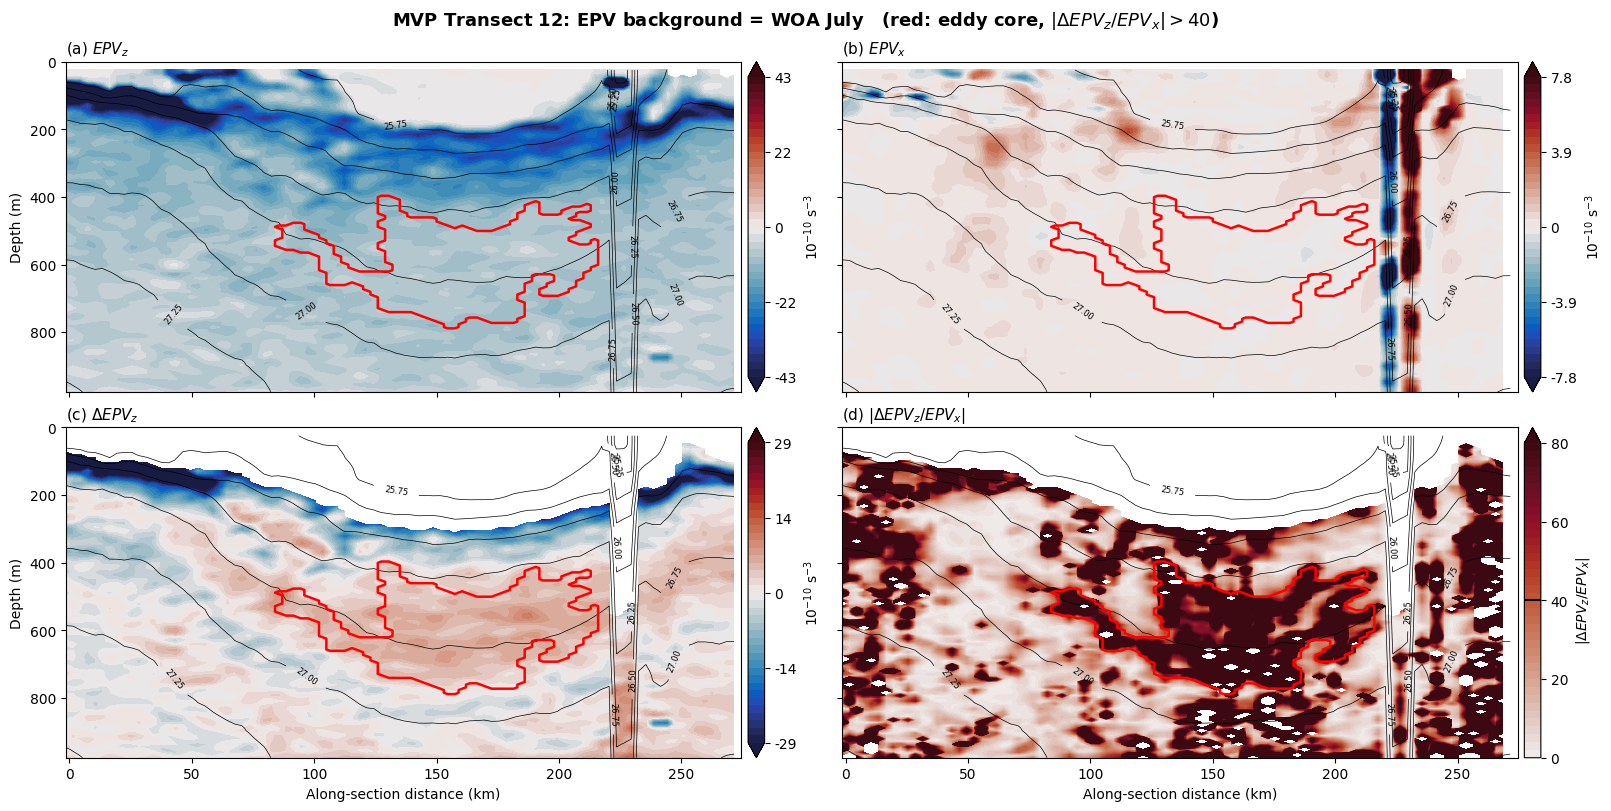

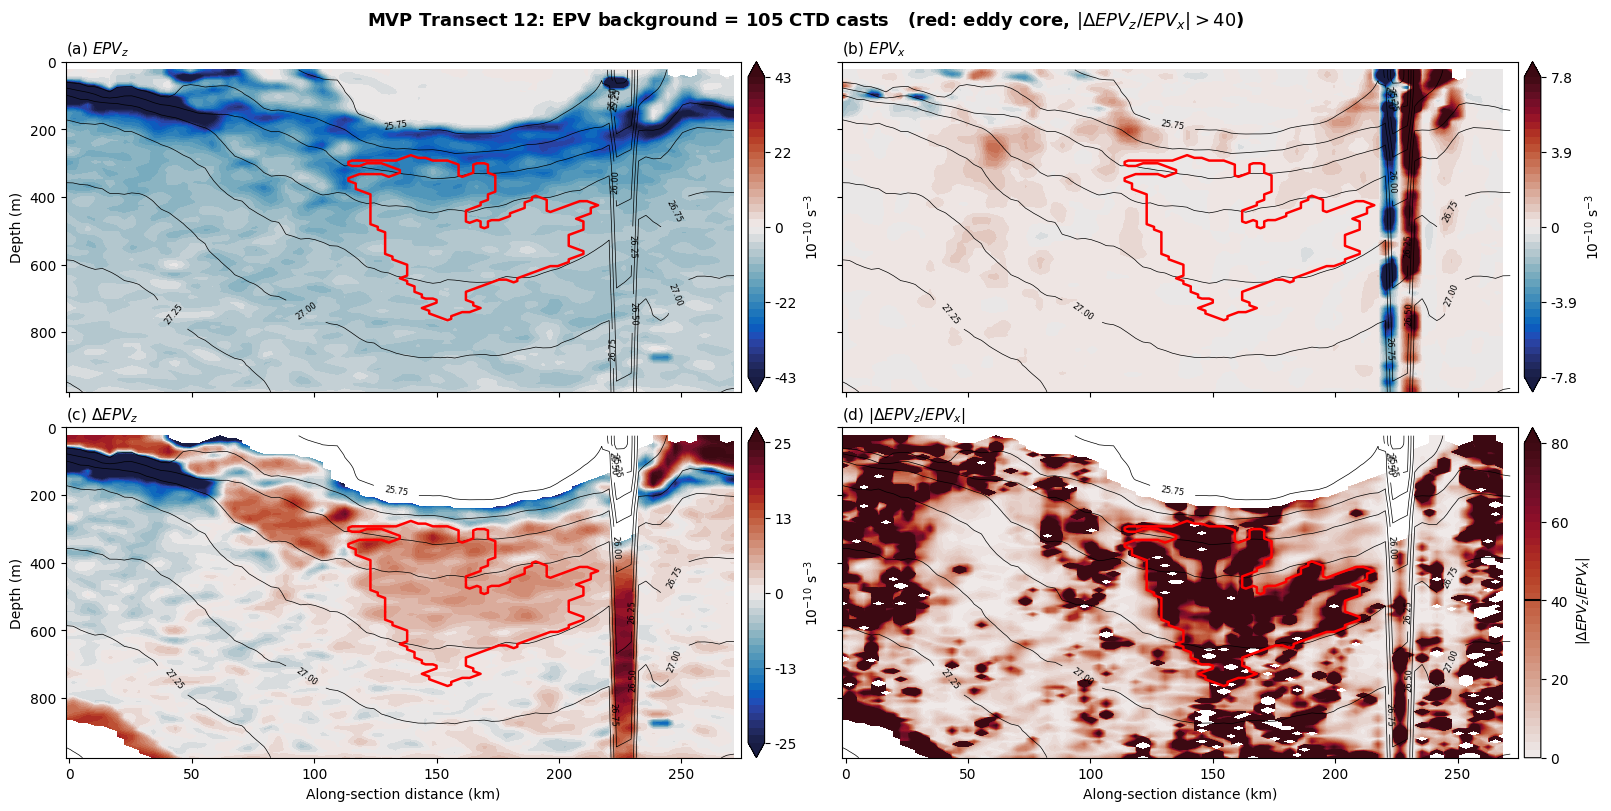

In [15]:
# ---------------- figures: one per background ----------------
EPV_SCALE = 1e-10       # plotted in units of 1e-10 s^-3
EPV_LIM = None          # colour limit for EPV_z, EPV_x, dEPV_z (in EPV_SCALE); None = 98th pct
R_MAX = 2 * BETA        # colour limit for |dEPV_z / EPV_x| in panel (d) (linear, 0 .. R_MAX)
flip_x = True
def plot_epv(epv, an, title="", savepath=None, flip_x=FLIP_X, zmax=ZMAX, core=None):
    """(a) EPV_z  (b) EPV_x  (c) EPV_z anomaly  (d) |dEPV_z / EPV_x| (linear), sigma0 contours.
    core: boolean (nx, nz) mask from eddy_core_mask, outlined in red on every panel."""
    import matplotlib.patheffects as pe
    x, z = epv["x"], epv["z"]
    fields = [(epv["EPV_z"], r"(a) $EPV_z$"),
              (epv["EPV_x"], r"(b) $EPV_x$"),
              (an["dEPV_z"], r"(c) $\Delta EPV_z$")]
    fig, axs = plt.subplots(2, 2, figsize=(16, 8), sharex=True, sharey=True, constrained_layout=True)
    axs = axs.ravel()
    for ax, (F, ttl) in zip(axs[:3], fields):
        Fs = F / EPV_SCALE
        lim = EPV_LIM or np.nanpercentile(np.abs(Fs), 98)
        lev = np.linspace(-lim, lim, 41)
        pc = ax.contourf(x, z, Fs.T, levels=lev, cmap=cmocean.cm.balance, extend="both")
        fig.colorbar(pc, ax=ax, pad=0.01, ticks=np.linspace(-lim, lim, 5),
                     format="%.2g").set_label(r"$10^{-10}$ s$^{-3}$")
        ax.set_title(ttl, loc="left", fontsize=11)
    absR = np.abs(an["R"])
    lev = np.linspace(0, R_MAX, 41)
    pc = axs[3].contourf(x, z, absR.T, levels=lev, cmap=cmocean.cm.amp, extend="max")
    cb = fig.colorbar(pc, ax=axs[3], pad=0.01, ticks=np.linspace(0, R_MAX, 5))
    cb.set_label(r"$|\Delta EPV_z / EPV_x|$")
    cb.ax.axhline(BETA, color="k", lw=1.5)                       # beta marked on the colour bar
    axs[3].set_title(rf"(d) $|\Delta EPV_z / EPV_x|$",
                     loc="left", fontsize=11)
    sig_lev = np.arange(np.floor(np.nanmin(epv["sig0"]) * 4) / 4, np.nanmax(epv["sig0"]), 0.25)
    for ax in axs:
        cs = ax.contour(x, z, epv["sig0"].T, levels=sig_lev, colors="k", linewidths=0.5)
        ax.clabel(cs, cs.levels, fontsize=6, fmt="%.2f")
        # ax.contour(x, z, epv["zeta"].T, levels=[0], colors="0.4", linewidths=1, linestyles="--")
        if core is not None and core.any():
            ax.contour(x, z, core.T.astype(float), levels=[0.5], colors="red", linewidths=1.8,
                       path_effects=[pe.Stroke(linewidth=3.2, foreground="white"), pe.Normal()])
        ax.set_ylim(min(zmax, z[-1]), 0)
    if flip_x:
        axs[0].invert_xaxis()
    for ax in axs[2:]:
        ax.set_xlabel("Along-section distance (km)")
    for ax in axs[::2]:
        ax.set_ylabel("Depth (m)")
    if core is not None:
        title += rf"   (red: eddy core, $|\Delta EPV_z / EPV_x| > {BETA}$)"
    fig.suptitle(title, fontsize=13, fontweight="bold")
    if savepath:
        fig.savefig(savepath, dpi=300)
    return fig, axs


for name, an in epv_anoms.items():
    ref_txt = (f"WOA July" if name == "WOA"
               else f"{len(ref_used)} CTD casts")
    fig, axs = plot_epv(epv, an, title=f"MVP {transect}: EPV background = {ref_txt}",
                        savepath=out_dir + f"{transect}_epv_{name.lower()}ref.png",
                        core=cores[name], flip_x = False)
    plt.show()